In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import bootstrap

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

ages = df["Age"].dropna().to_numpy()

In [3]:
#Calculate bootstrap confidence intervals

rng = np.random.default_rng(42)

result = bootstrap(
    (ages,),
    np.mean,
    n_resamples=10000,
    confidence_level=0.95,
    method="BCa",
    rng=rng
)

print("Sample Mean:", np.mean(ages))
print("Confidence Interval:", result.confidence_interval)
print("Standard Error:", result.standard_error)

Sample Mean: 29.69911764705882
Confidence Interval: ConfidenceInterval(low=np.float64(28.65946754296629), high=np.float64(30.793919895361768))
Standard Error: 0.5457663133828472


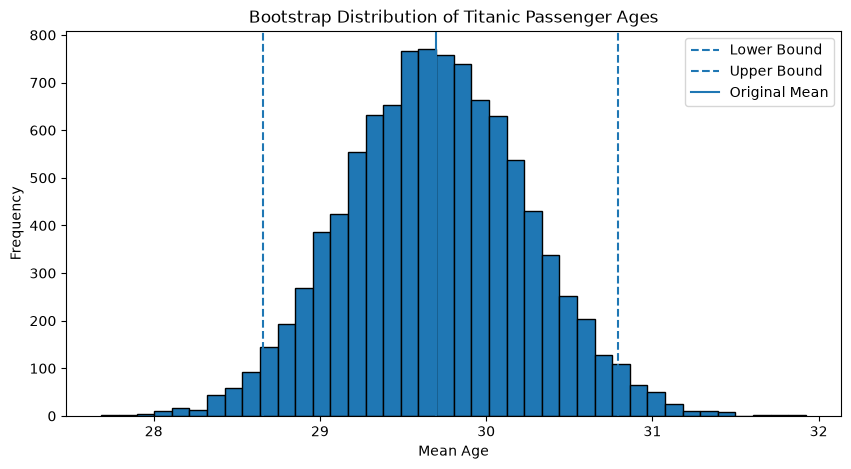

In [4]:
#   Visualize 

plt.figure(figsize=(10, 5))

plt.hist(
    result.bootstrap_distribution,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    result.confidence_interval.low,
    linestyle="--",
    label="Lower Bound"
)

plt.axvline(
    result.confidence_interval.high,
    linestyle="--",
    label="Upper Bound"
)

plt.axvline(
    np.mean(ages),
    linestyle="-",
    label="Original Mean"
)

plt.title("Bootstrap Distribution of Titanic Passenger Ages")
plt.xlabel("Mean Age")
plt.ylabel("Frequency")
plt.legend()
plt.show()